# POC 01b — latent trajectories of stored runs (all · commissioning · streaming)

Reads the runs POC_04 trained; trains nothing. For each schedule it uses the object that is
one encoder applied to every month:

| schedule | trajectory object | what it is | not usable for full-horizon trajectories |
|---|---|---|---|
| `all` | `local` (last round), `post_fedavg_full` | per-client monthly mean latent, pre-FedAvg / final global model on all windows | — |
| `comm` | `post_fedavg_full` | the **frozen** commissioning encoder on every month | `local`, `global`, snapshots: init months only (the trainer saw only those) |
| `stream` | `block_full` at each block end | global model **as it stood after block b**, on every month | `local`: each month only in its own block's rounds |

`block_full` and the all-month stream snapshots exist only for stream runs trained with the
block-end snapshot change (POC_04 v3 cell 7 retrains older ones).

## 0. Setup

In [1]:
import sys, pathlib, re, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

REPO = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / "src" / "fedwater").is_dir()), None)
assert REPO is not None, "run this from inside the fedwater repo"
LAB_DIR = REPO / "notebooks" / "fedwater_lab_refactor"
for p in (REPO / "src", LAB_DIR):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from fedwater_lab.worlds import load_world, pick_world
from fedwater_lab.store import Store
from fedwater_lab import data as D, metrics as M, train as T, figures as F
from fedwater_lab import widgets as WGT
from fedwater_lab.aligned import encode_windows
import prototype_views as PV
importlib.reload(PV)          # picks up the half-open phase fix

EXPERIMENTS = REPO / "data" / "09_experiments"
pd.set_option("display.width", 220, "display.max_columns", 40)

## 1. World

tag               District_C__LC_LR_LR_LC_LI__baseline
n_months                                            71
init_months                                      0..11
final_months                                    34..70
drift_district                              District_C
first_switch                                        12
last_switch                                         33
phases (half-open [lo, hi)): {'init': (0, 12), 'final': (34, 71)}


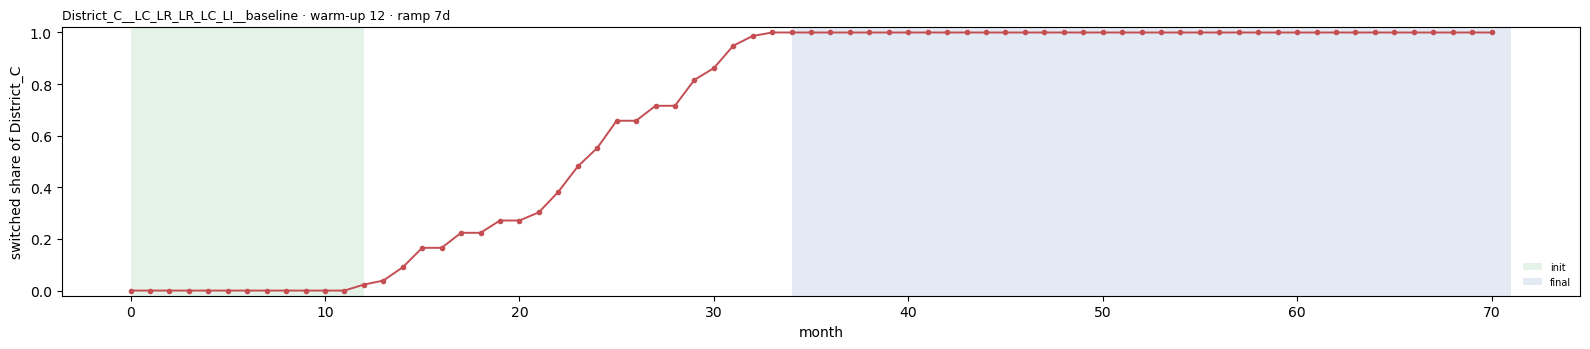

In [2]:
FILTERS = dict(sim_hash="0ed323104afb", placement_source="dynamic") # 1ca8610b6a11
world = load_world(pick_world(EXPERIMENTS, **FILTERS))
store = Store(LAB_DIR / "lab_sandbox")
PH = world.phases()
print(world.summary()[["tag", "n_months", "init_months", "final_months",
                       "drift_district", "first_switch", "last_switch"]].to_string())
print(f"phases (half-open [lo, hi)): {PH}")

fig, ax = plt.subplots(figsize=(16, 3.6))
F.plot_drift_progress(ax, world)
fig.tight_layout()
plt.show()

## 2. Pick the runs

`store.index` holds every run of this world. The label carries the loss terms (`__L…`) and the
schedule (`__C<lo>-<hi>` commissioning, `__S<B>x<R>[w<W>]` streaming, nothing = all months).
`LABEL_RE` narrows to the POC_04 cells (flow orientation, `a3w84s4`, 5 local epochs). If more than
one run matches a (loss, schedule) pair the cell stops: set `PICK` by hand.

In [3]:
def schedule_of(label: str) -> str:
    last = label.split("__")[-1]
    if re.fullmatch(r"C\d+-\d+", last):
        return "comm"
    if re.fullmatch(r"S\d+x\d+(w\d+)?", last):
        return "stream"
    return "all"


def loss_of(label: str) -> str:
    p = [x for x in label.split("__") if x.startswith("L")]
    return p[0] if p else "none"


IDX = store.index(world.sim_hash).copy()
IDX["schedule"] = IDX["label"].map(schedule_of)
IDX["loss"] = IDX["label"].map(loss_of)
display(IDX[["run_key", "label", "schedule", "loss", "rounds", "n_windows", "saved_at"]])

LABEL_RE = (r"\+or__", r"__a3w84s4__", r"__u\d+r\d+e5")
cand = IDX[np.logical_and.reduce([IDX["label"].str.contains(rx, regex=True)
                                  for rx in LABEL_RE])]
dup = cand[cand.duplicated(["loss", "schedule"], keep=False)]
if len(dup):
    display(dup)
    raise ValueError("several runs per (loss, schedule) -- set PICK by hand")
PICK = {f"{r.loss}·{r.schedule}": r.run_key
        for r in cand.sort_values(["loss", "schedule"]).itertuples()}
# PICK = {"Lp0·comm": "<run_key>", ...}     # explicit override
PICK

,run_key,label,schedule,loss,rounds,n_windows,saved_at
0,349ab4ddadef,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,all,Lp0,30,11310,2026-10-13 12:27:00
1,7606540f9c7d,fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0_...,comm,Lp0,95,11310,2026-10-13 12:42:50
2,8f178712b99f,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,stream,Lp0,30,0,2026-10-13 12:58:48
3,ba29d1f1e97a,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,all,Lp0.1-s1,30,11310,2026-10-13 13:31:59
4,1d6fd72b3b32,fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0_...,comm,Lp0.1-s1,95,11310,2026-10-13 13:49:38
5,0835ac99e165,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,stream,Lp0.1-s1,30,0,2026-10-13 14:07:01


{'Lp0·all': '349ab4ddadef',
 'Lp0·comm': '7606540f9c7d',
 'Lp0·stream': '8f178712b99f',
 'Lp0.1-s1·all': 'ba29d1f1e97a',
 'Lp0.1-s1·comm': '1d6fd72b3b32',
 'Lp0.1-s1·stream': '0835ac99e165'}

## 3. Load, coverage, sanity

Loading reads the persisted tables only. `FW` rebuilds each run's windows from its **saved**
spec (orientation, geometry, scaler) — needed by the untrained-control check.

**Coverage** lists, per table / scope, the rounds and months present: it is the quickest way to
see what each schedule can and cannot show.

In [4]:
RES, SPEC, SCHED, FW = {}, {}, {}, {}
for name, key in PICK.items():
    r = store.load_run(world.sim_hash, key)
    r["snapshots"], r["run_key"] = r.get("latents_by_round"), key
    sp = r["spec"]
    s = ("all" if sp.schedule is None else
         "comm" if sp.schedule.mode == "commissioning" else "stream")
    assert s == schedule_of(r["meta"]["label"]), f"{name}: spec says {s}"
    if s == "stream":
        b = r["meta"].get("blocks") or []
        assert b and "r_hi" in b[0], (f"{name}: saved before the block-end snapshot "
                                      f"change -- rerun POC_04 v3 cell 7")
    RES[name], SPEC[name], SCHED[name] = r, sp, s
    FW[name], _, _ = D.build_windows(world, sp, cache=D.CACHE)
    print(f"{name:<22} {key}  {s:<6} {r['meta']['label']}")


def coverage(res) -> pd.DataFrame:
    rows = []
    def add(tab, g):
        rows.append({"table": tab, "rounds": g["round"].nunique() if "round" in g else 1,
                     "round range": (f"{g['round'].min()}..{g['round'].max()}"
                                     if "round" in g else "final"),
                     "months": g["month"].nunique(),
                     "month range": f"{g['month'].min()}..{g['month'].max()}"})
    for sc, g in res["prototypes"].groupby("scope"):
        add(f"prototypes · {sc}", g)
    if res["snapshots"] is not None:
        for st, g in res["snapshots"].groupby("stage"):
            add(f"snapshots · {st}", g)
    add("latent_trajectories", res["latent_trajectories"])
    if res.get("latent_trajectories_preq") is not None:
        add("latent_trajectories_preq", res["latent_trajectories_preq"])
    return pd.DataFrame(rows)


display(pd.concat({n: coverage(RES[n]) for n in RES}, names=["run"]))

Lp0·all                349ab4ddadef  all    fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0__Lp0
Lp0·comm               7606540f9c7d  comm   fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0__Lp0__C0-11
Lp0·stream             8f178712b99f  stream fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0__Lp0__S6x16w10
Lp0.1-s1·all           ba29d1f1e97a  all    fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0__Lp0.1-s1
Lp0.1-s1·comm          1d6fd72b3b32  comm   fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0__Lp0.1-s1__C0-11
Lp0.1-s1·stream        0835ac99e165  stream fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0__Lp0.1-s1__S6x16w10


table  rounds round range  months month range
run                                                                                     
Lp0·all         0            prototypes · global      30       0..29      71       0..70
                1             prototypes · local      30       0..29      71       0..70
                2       prototypes · post_fedavg       3       0..29      71       0..70
                3  prototypes · post_fedavg_full       1      29..29      71       0..70
                4               snapshots · post       3       0..29      71       0..70
                5                snapshots · pre       4      -1..29      71       0..70
                6            latent_trajectories       1       final      71       0..70
Lp0·comm        0            prototypes · global      95       0..94      12       0..11
                1             prototypes · local      95       0..94      12       0..11
                2       prototypes · post_fedavg       3       0..94      12       0..11
                3  prototypes · post_fedavg_full       1      94..94      71       0..70
                4               snapshots · post       3       0..94      12       0..11
                5                snapshots · pre       4      -1..94      12       0..11
                6            latent_trajectories       1       final      71       0..70
Lp0·stream      0        prototypes · block_full      13     -1..185      71       0..70
                1            prototypes · global     186      0..185      71       0..70
                2             prototypes · local     186      0..185      71       0..70
                3       prototypes · post_fedavg      12      9..185      71       0..70
                4  prototypes · post_fedavg_full       1    185..185      71       0..70
                5               snapshots · post      12      9..185      71       0..70
                6                snapshots · pre      13     -1..185      71       0..70
                7            latent_trajectories       1       final      71       0..70
                8       latent_trajectories_preq       1       final      71       0..70
Lp0.1-s1·all    0            prototypes · global      30       0..29      71       0..70
                1             prototypes · local      30       0..29      71       0..70
                2       prototypes · post_fedavg       3       0..29      71       0..70
                3  prototypes · post_fedavg_full       1      29..29      71       0..70
                4               snapshots · post       3       0..29      71       0..70
                5                snapshots · pre       4      -1..29      71       0..70
                6            latent_trajectories       1       final      71       0..70
Lp0.1-s1·comm   0            prototypes · global      95       0..94      12       0..11
                1             prototypes · local      95       0..94      12       0..11
                2       prototypes · post_fedavg       3       0..94      12       0..11
                3  prototypes · post_fedavg_full       1      94..94      71       0..70
                4               snapshots · post       3       0..94      12       0..11
                5                snapshots · pre       4      -1..94      12       0..11
                6            latent_trajectories       1       final      71       0..70
Lp0.1-s1·stream 0        prototypes · block_full      13     -1..185      71       0..70
                1            prototypes · global     186      0..185      71       0..70
                2             prototypes · local     186      0..185      71       0..70
                3       prototypes · post_fedavg      12      9..185      71       0..70
                4  prototypes · post_fedavg_full       1    185..185      71       0..70
                5               snapshots · post      12      9..185      71       0..70
                6                snaps

**Checks.** `M.check_run` as in POC_01, plus:

* `untrained == round -1 snapshot` — the rebuilt init (`T.untrained_model`) must reproduce the
  saved round −1 latents on the same windows (atol 1e-5; GPU vs CPU).
* **stream**: `global_proto_rounds` is compared with `meta.rounds` (cumulative over blocks;
  `fl.training.rounds` is the base spec's and means nothing here); snapshot rounds are exactly
  {−1} ∪ block ends; every snapshot slice covers every month; the last `block_full` equals
  `post_fedavg_full` (same weights, same windows); and
  `preq block b == block_full at end of b−1` — the prequential latents of block $b$ were
  encoded by the model that ended block $b-1$, so their monthly means must equal that round's
  `block_full` rows (atol 1e-4: different batch composition on GPU).
* **comm**: every trained month lies inside the commissioning months.

In [5]:
def _maxabs(j, fc):
    return (float(np.abs(j[fc].to_numpy() - j[[f + "_r" for f in fc]].to_numpy()).max())
            if len(j) else np.nan)


def untrained_check(name):
    res, sn = RES[name], RES[name]["snapshots"]
    s = sn[sn["round"] == -1] if sn is not None else pd.DataFrame()
    if not len(s):
        return ("untrained == round -1 snapshot", "no round -1", False)
    z = encode_windows(T.untrained_model(res), FW[name])
    fc = F.fcols(s)
    j = s[["district", "window"] + fc].merge(z[["district", "window"] + fc],
                                             on=["district", "window"], suffixes=("", "_r"))
    d = _maxabs(j, fc)
    return ("untrained == round -1 snapshot", round(d, 8), len(j) == len(s) and d < 1e-5)


def blocks_of(name) -> pd.DataFrame:
    return pd.DataFrame(RES[name]["meta"]["blocks"]).dropna(subset=["r_hi"]) \
             .astype({"r_lo": int, "r_hi": int})


def preq_check(name):
    res = RES[name]
    pr, lp = res["prototypes"], res["latent_trajectories_preq"]
    bf, fc = pr[pr["scope"] == "block_full"], F.fcols(lp)
    blocks = blocks_of(name)
    before = [-1] + blocks["r_hi"].tolist()[:-1]
    ds, ok = [], True
    for b, rb in zip(blocks["block"], before):
        q = (lp[lp["block"] == b].groupby(["district", "month"])[fc].mean()
             .reset_index().rename(columns={"district": "client"}))
        j = q.merge(bf[bf["round"] == rb], on=["client", "month"], suffixes=("", "_r"))
        ok &= len(j) == len(q)
        ds.append(_maxabs(j, fc))
    d = float(np.nanmax(ds))
    return ("preq block b == block_full at end of b-1", round(d, 8), ok and d < 1e-4)


def schedule_checks(name) -> pd.DataFrame:
    res, s, meta = RES[name], SCHED[name], RES[name]["meta"]
    chk = M.check_run(res, world)
    extra = [untrained_check(name)]
    if s == "stream":
        n = int(res["global_prototype_history"]["round"].nunique())
        i = chk.index[chk["check"] == "global_proto_rounds"]
        chk.loc[i, "check"] = "global_proto_rounds (vs meta.rounds)"
        chk.loc[i, "value"] = n
        chk.loc[i, "passed"] = n == int(meta["rounds"])
        want = {-1} | set(blocks_of(name)["r_hi"])
        got = set(res["snapshots"]["round"].astype(int))
        extra.append(("snapshot rounds == {-1} + block ends", len(got), got == want))
        allm = set(res["latent_trajectories"]["month"])
        cov = all(set(g["month"]) == allm
                  for _, g in res["snapshots"].groupby(["round", "stage"]))
        extra.append(("every snapshot slice covers every month", len(allm), cov))
        pr = res["prototypes"]
        bf = pr[pr["scope"] == "block_full"]
        bf = bf[bf["round"] == bf["round"].max()]
        pf = pr[pr["scope"] == "post_fedavg_full"]
        j = bf.merge(pf, on=["client", "month"], suffixes=("", "_r"))
        d = _maxabs(j, F.fcols(pf))
        extra.append(("last block_full == post_fedavg_full", round(d, 8),
                      len(j) == len(pf) and d < 1e-5))
        extra.append(preq_check(name))
    elif s == "comm":
        lo, hi = SPEC[name].schedule.months
        tm = res["prototype_history"]["month"]
        extra.append(("trained months within commissioning months",
                      f"{tm.min()}..{tm.max()} in {lo}..{hi}",
                      bool(tm.min() >= lo and tm.max() <= hi)))
    return pd.concat([chk, pd.DataFrame(extra, columns=chk.columns)], ignore_index=True)


CHECKS = pd.concat({n: schedule_checks(n) for n in RES}, names=["run"])
display(CHECKS)
assert CHECKS["passed"].astype(bool).all(), "a check failed -- read the table before the figures"

check  value  passed
run                                                                        
Lp0·all         0                                 latent_dim     60    True
                1                              prototype_dim     60    True
                2                     latent_rows == windows  11310    True
                3                             latents_finite   True    True
                4                          prototypes_finite   True    True
...                                                      ...    ...     ...
Lp0.1-s1·stream 9             untrained == round -1 snapshot    0.0    True
                10      snapshot rounds == {-1} + block ends   13.0    True
                11   every snapshot slice covers every month   71.0    True
                12       last block_full == post_fedavg_full    0.0    True
                13  preq block b == block_full at end of b-1    0.0    True

[70 rows x 3 columns]

### 3b. Streaming regression — did the snapshot change alter training?

POC_04 v3 backs up each stream run before retraining it. Snapshots are taken on copies of the
weights, so the retrained run should match the backup on everything training produced. Reported
as the max absolute difference per table (0 = identical); a non-zero value means either the
change touched training or training itself is not deterministic on this machine — the two are
not separable from this table alone.

In [6]:
BACKUP = store.root / "backup_pre_block_snapshots" / world.sim_hash


def _read(base: pathlib.Path):
    for suf, rd in ((".parquet", pd.read_parquet), (".csv.gz", pd.read_csv),
                    (".csv", pd.read_csv)):
        if base.with_suffix(suf).exists():
            return rd(base.with_suffix(suf))
    return None


def regression(name) -> pd.DataFrame | None:
    old = BACKUP / PICK[name]
    if not old.exists():
        return None
    res, rows = RES[name], []
    for tab, keys in (("training_log", ["round", "client"]),
                      ("prequential", ["block", "client", "model"]),
                      ("prototype_history", ["round", "client", "month"])):
        a, b = _read(old / tab), res.get(tab)
        if a is None or b is None:
            rows.append({"table": tab, "rows old/new": "missing", "max_abs_diff": np.nan})
            continue
        k = [c for c in keys if c in a.columns and c in b.columns]
        if k:
            a, b = a.sort_values(k), b.sort_values(k)
        a, b = a.reset_index(drop=True), b.reset_index(drop=True)
        num = [c for c in a.select_dtypes("number").columns
               if c in b.columns and c not in k]
        same = len(a) == len(b)
        d = float(np.nanmax(np.abs(a[num].to_numpy(float) - b[num].to_numpy(float)))) \
            if same and num else np.nan
        rows.append({"table": tab, "rows old/new": f"{len(a)}/{len(b)}", "max_abs_diff": d})
    return pd.DataFrame(rows)


REG = {n: regression(n) for n in RES if SCHED[n] == "stream"}
REG = {n: v for n, v in REG.items() if v is not None}
display(pd.concat(REG, names=["run"]) if REG else "no backups found (nothing was retrained)")

'no backups found (nothing was retrained)'

## 4. Prototype trajectories over months

For client $c$, month $m$, prototype $p_c(m)$ of one scope at one round (`prototype_views`):

* **reference distance** $d_c(m) = 1-\cos\big(p_c(m),\,\mu_c^{init}\big)$, with
  $\mu_c^{init}$ the mean of $p_c$ over the init months — how far the client's representation
  has moved from its own commissioning state. A drift detector reads this per client: the
  drifting district should rise after `first_switch`, the others stay flat.
* **transition axis** (shared): $v=\mu^{final}-\mu^{init}$ (means of the per-client
  centroids), $x=p_c(m)-\mu^{init}$, $t=\langle x,v\rangle/\lVert v\rVert^2$ (0 = init
  regime, 1 = final regime) and the off-axis residual $\lVert x-tv\rVert$ — movement the
  regime shift does not explain.
* **heatmap** $z_{c,k}(m)=(p_{c,k}(m)-\mu^{init}_{c,k})/\sigma_k$, $\sigma_k$ pooled over the
  round — which latent dimensions carry the movement.

Caveat: `final` is short in this world, so $\mu^{final}$ (and therefore $t$) rests on very
few months — read $t$ as a direction, not a calibrated scale.

`VIEWS` sets which (scope, round) each schedule is read through; `None` = the scope's last round.
The tables are saved to `scores/trajectory_views` (one row per run × scope × round × client ×
month), so the figures can be redrawn without the notebook state.

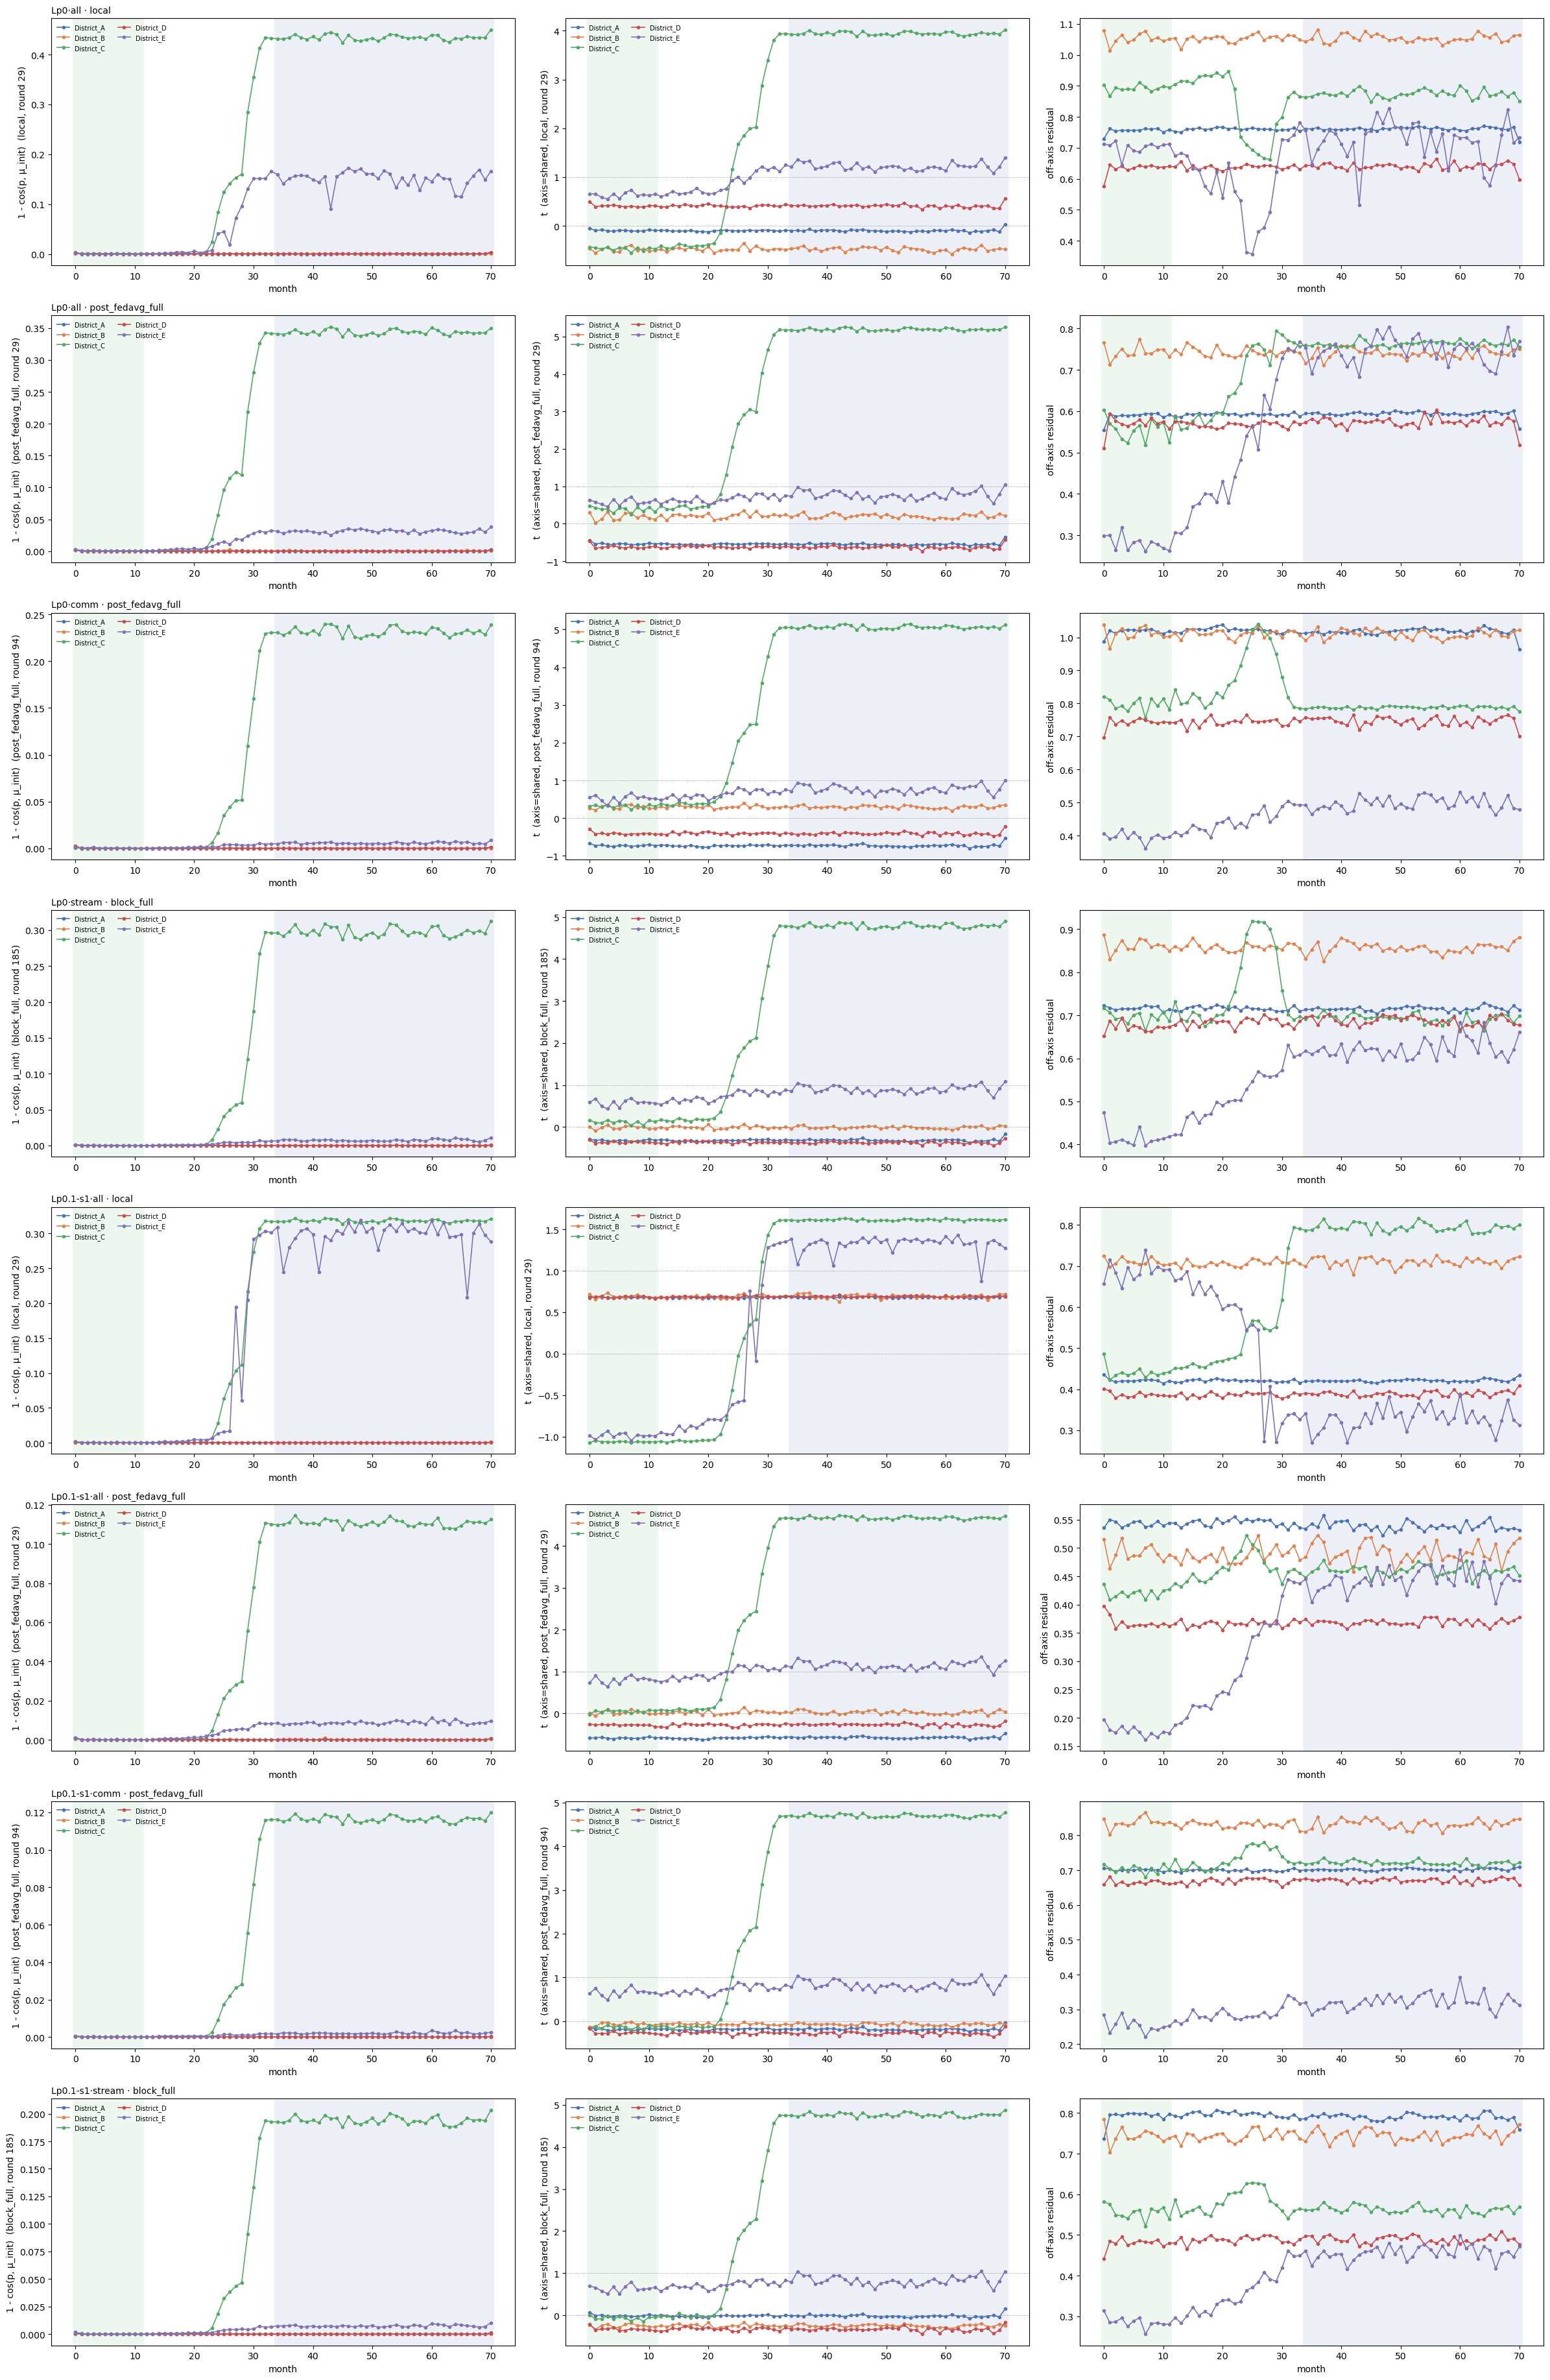

WindowsPath('C:/Users/arthu/USPy/10_Mestrado/fedWater/notebooks/fedwater_lab_refactor/lab_sandbox/scores/trajectory_views.parquet')

In [7]:
VIEWS = {"all":    [("local", None), ("post_fedavg_full", None)],
         "comm":   [("post_fedavg_full", None)],
         "stream": [("block_full", None)]}
TRANSITION_AXIS = "shared"            # or "client": each client's own init -> final axis
PANELS = [(n, sc, r) for n in RES for sc, r in VIEWS[SCHED[n]]]

rows = []
fig, axes = plt.subplots(len(PANELS), 3, figsize=(24, 4.6 * len(PANELS)), squeeze=False)
for i, (n, sc, r) in enumerate(PANELS):
    pr = RES[n]["prototypes"]
    PV.plot_reference_distance(axes[i, 0], pr, world, sc, r)
    PV.plot_transition_axis(axes[i, 1], axes[i, 2], pr, world, sc, r, axis=TRANSITION_AXIS)
    axes[i, 0].set_title(f"{n} · {sc}", fontsize=10, loc="left")
    rd = PV.reference_distance(pr, world, sc, r)
    tc = PV.transition_coordinates(pr, world, sc, r, axis=TRANSITION_AXIS)
    rows.append(rd.merge(tc, on=["client", "month"])
                  .assign(run=n, run_key=PICK[n], schedule=SCHED[n], scope=sc,
                          round=rd.attrs["round"], axis=TRANSITION_AXIS))
fig.tight_layout()
plt.show()

TRAJ = pd.concat(rows, ignore_index=True)
store.save_scores("trajectory_views", TRAJ.assign(world_hash=world.sim_hash),
                  keys=("world_hash", "run_key", "scope", "round", "axis", "client", "month"))

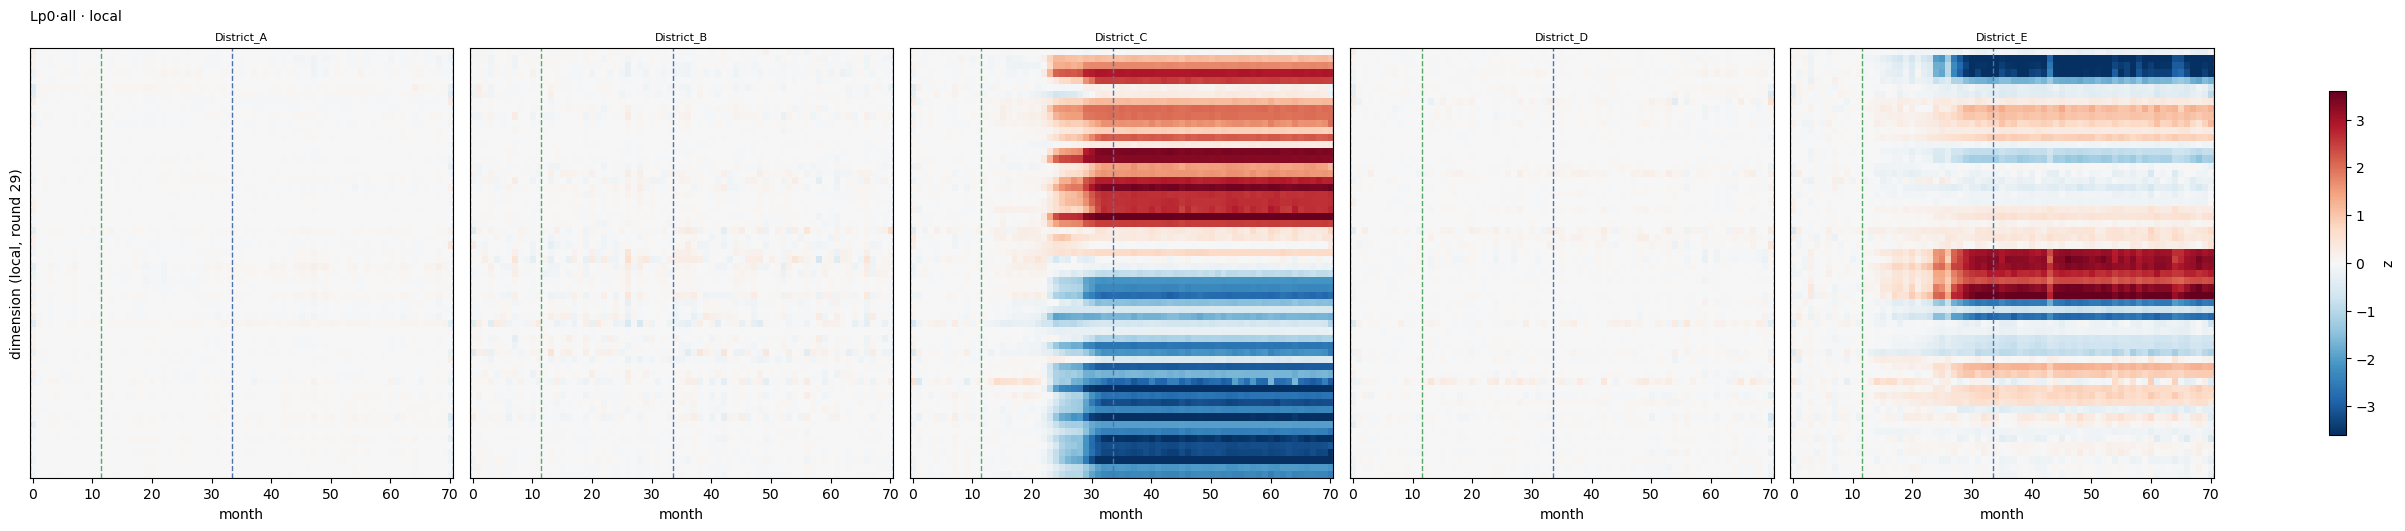

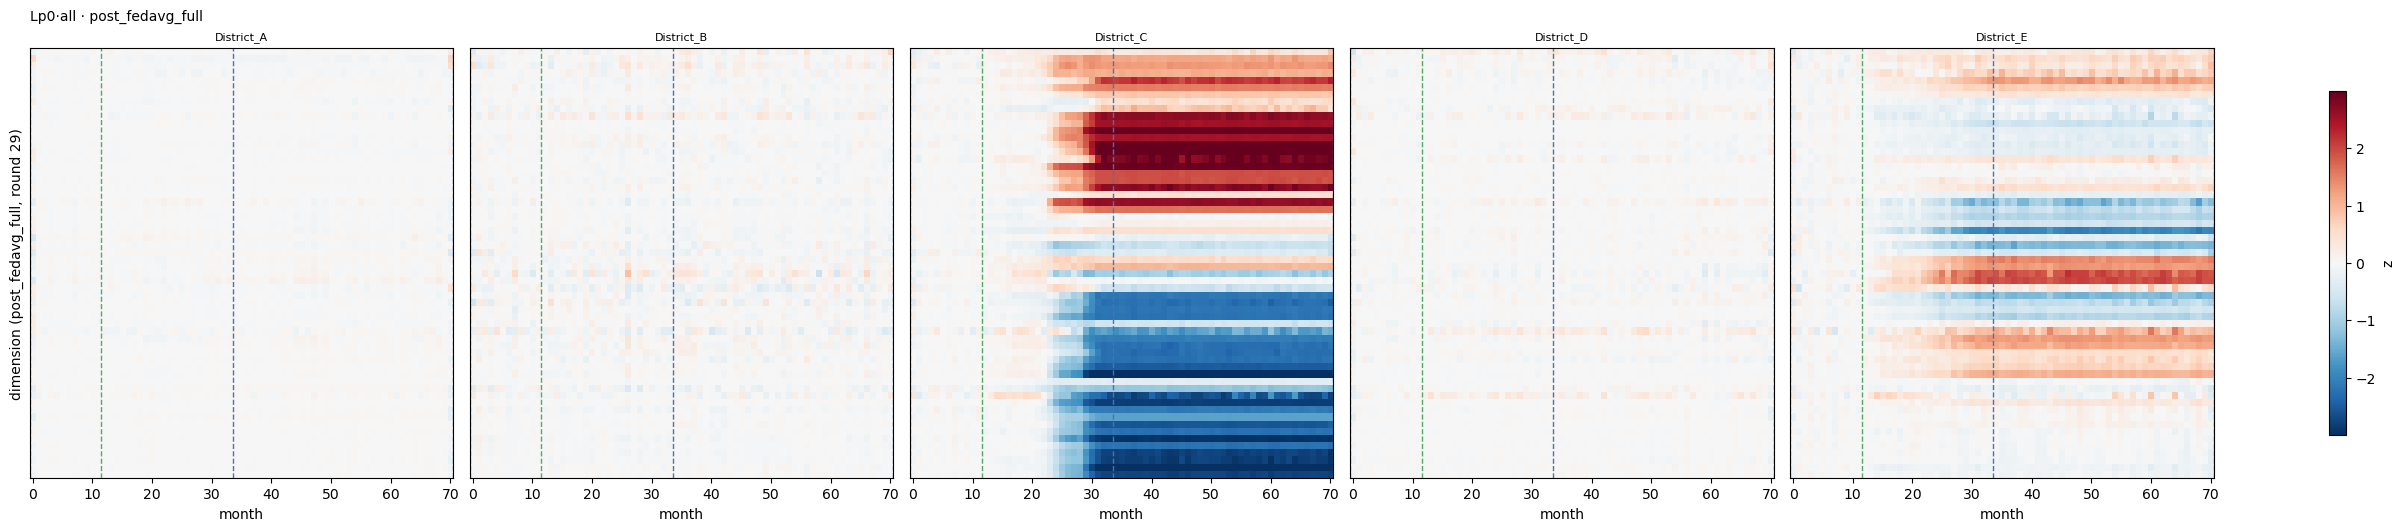

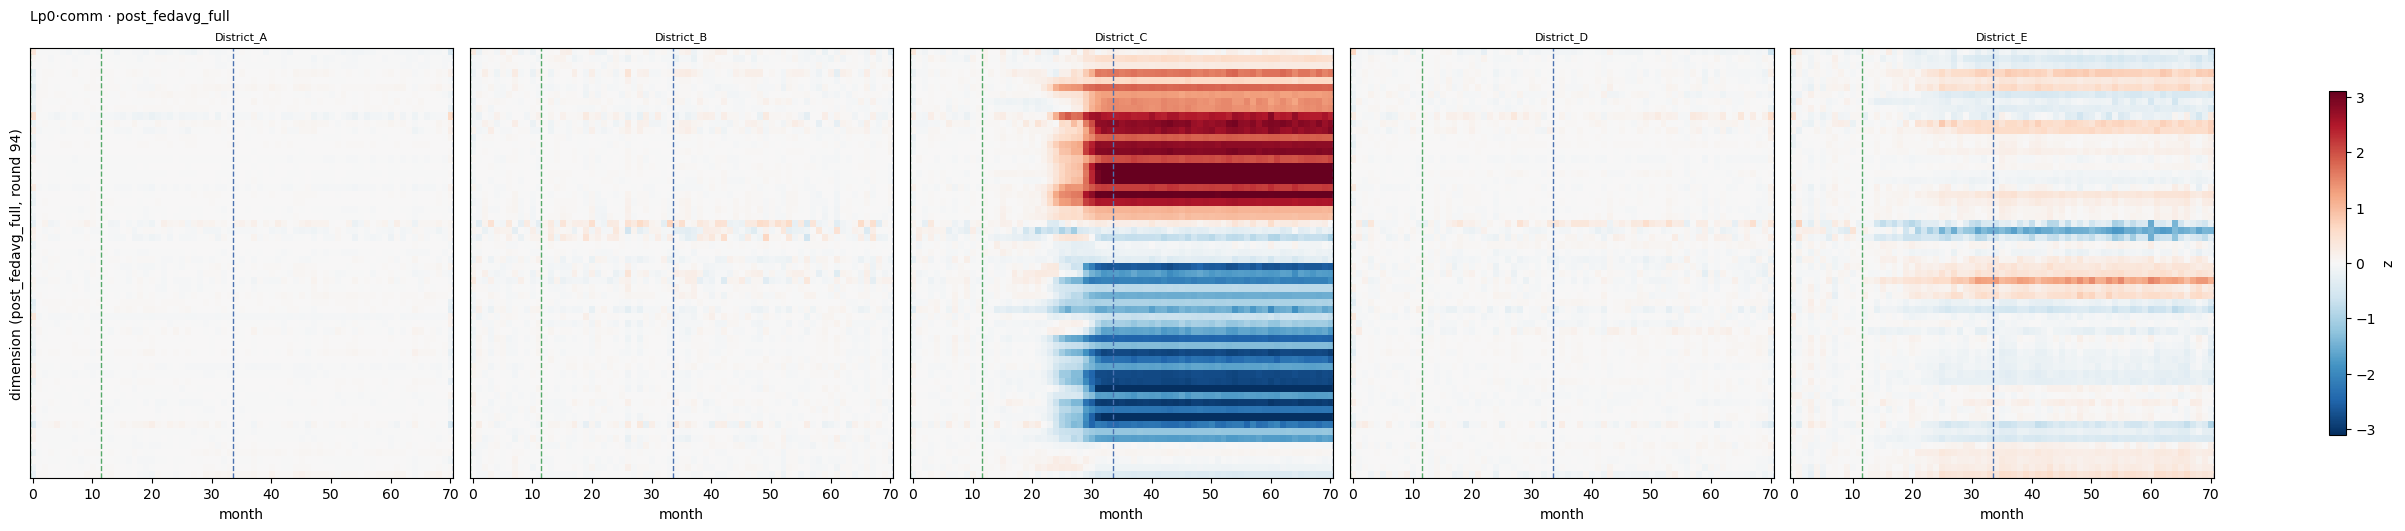

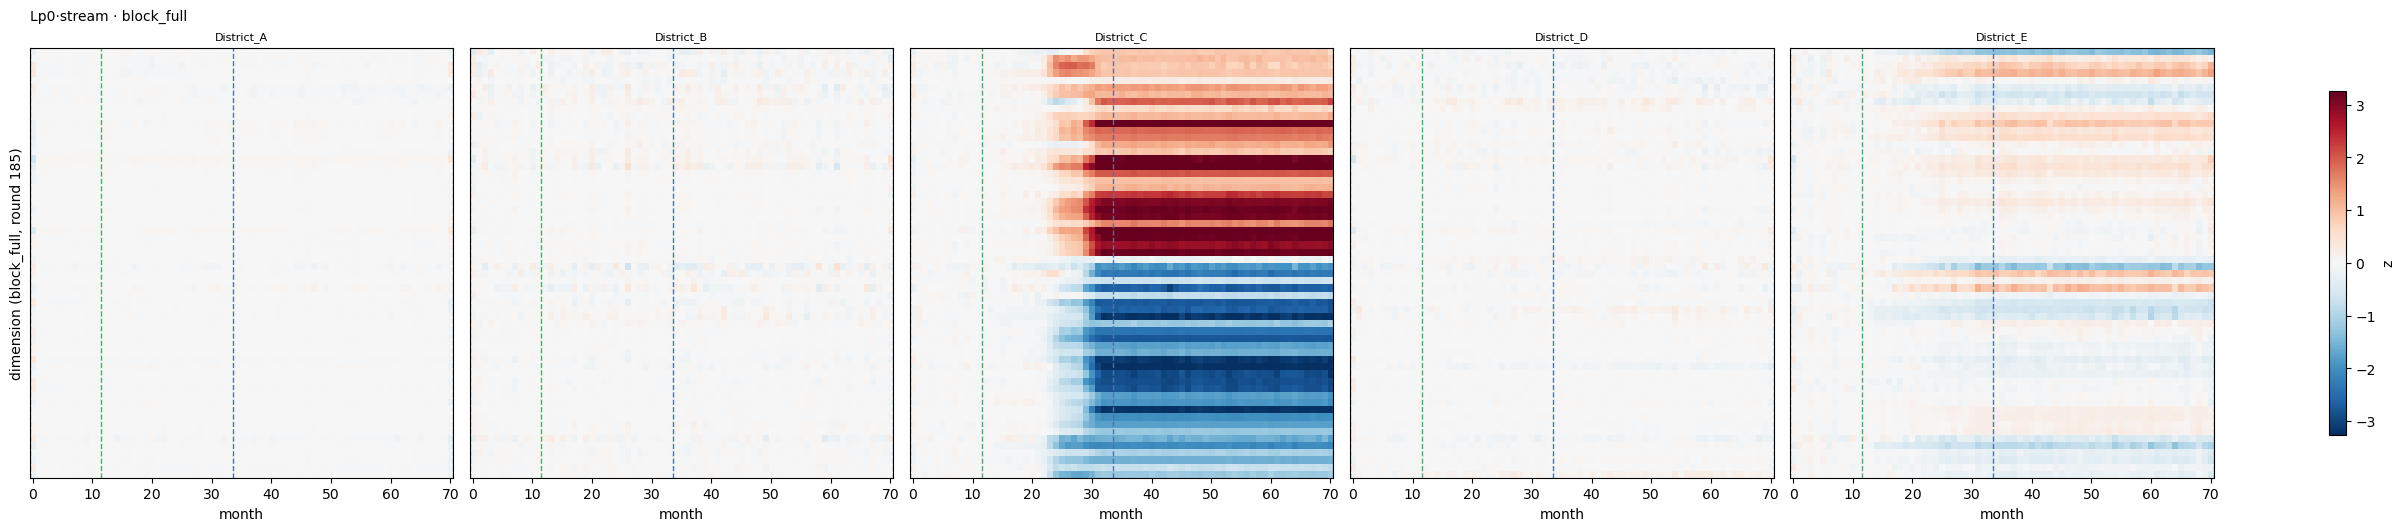

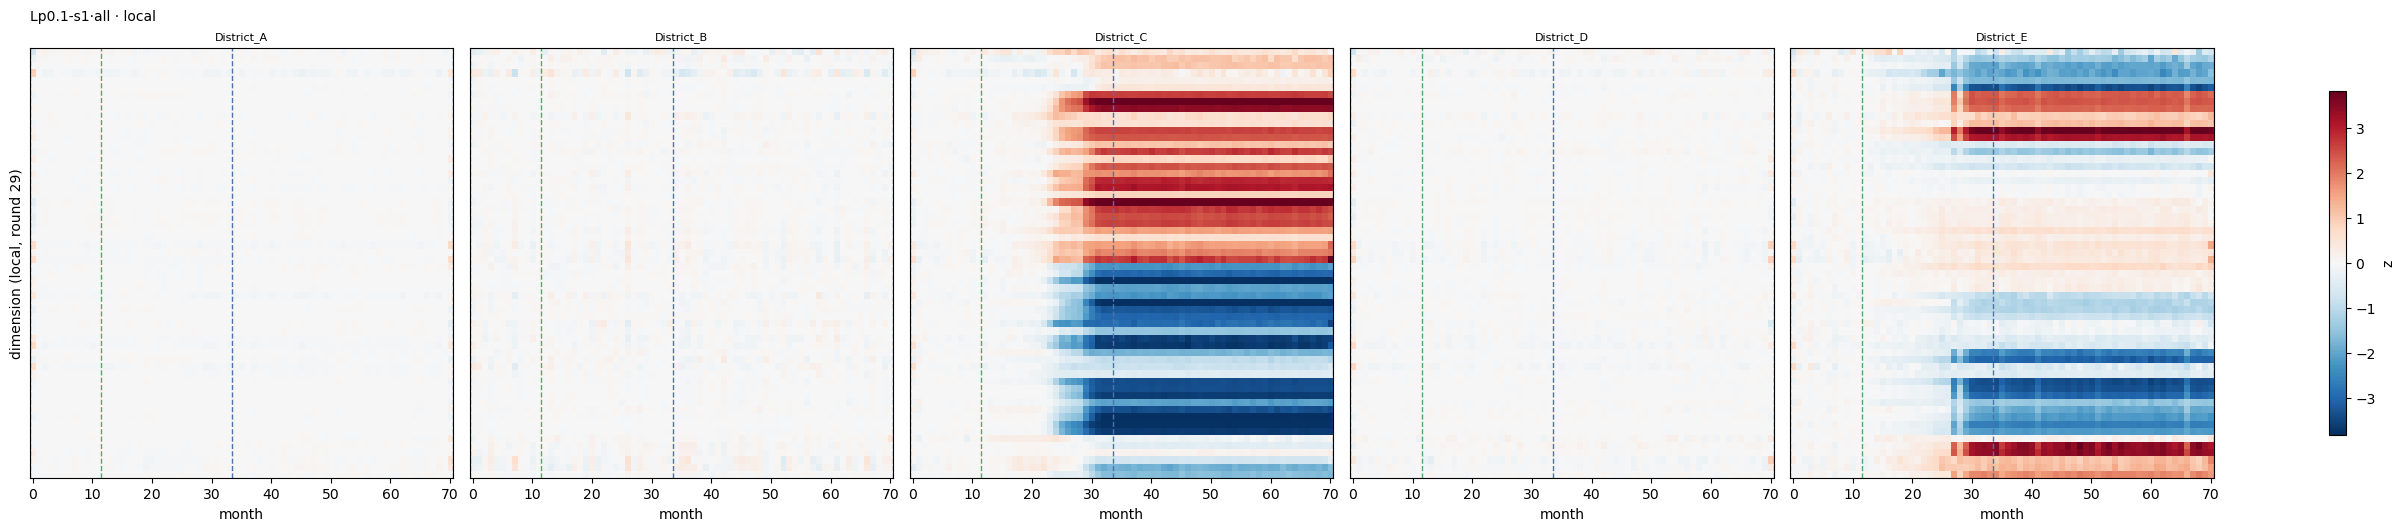

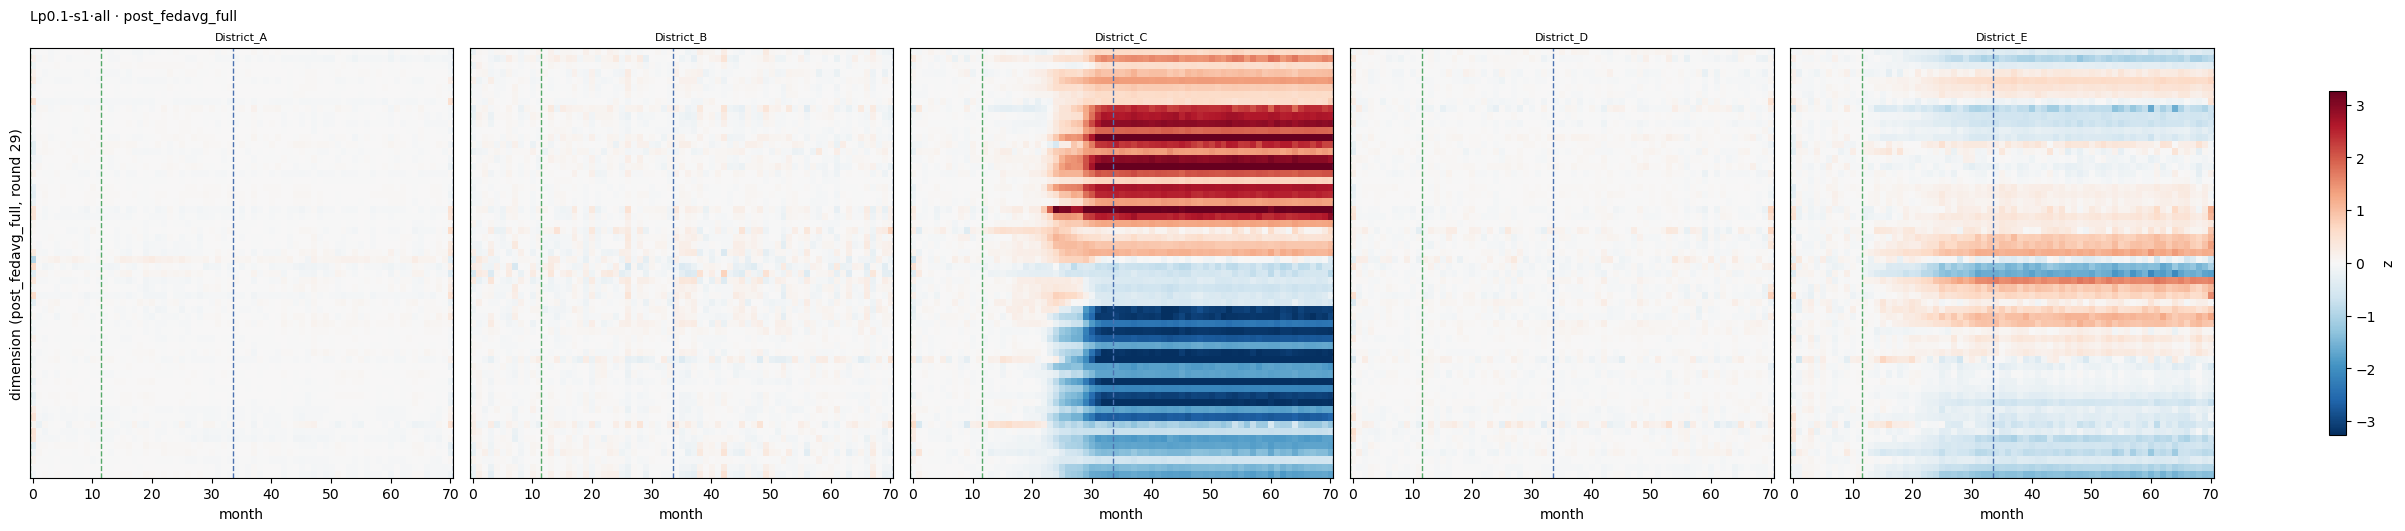

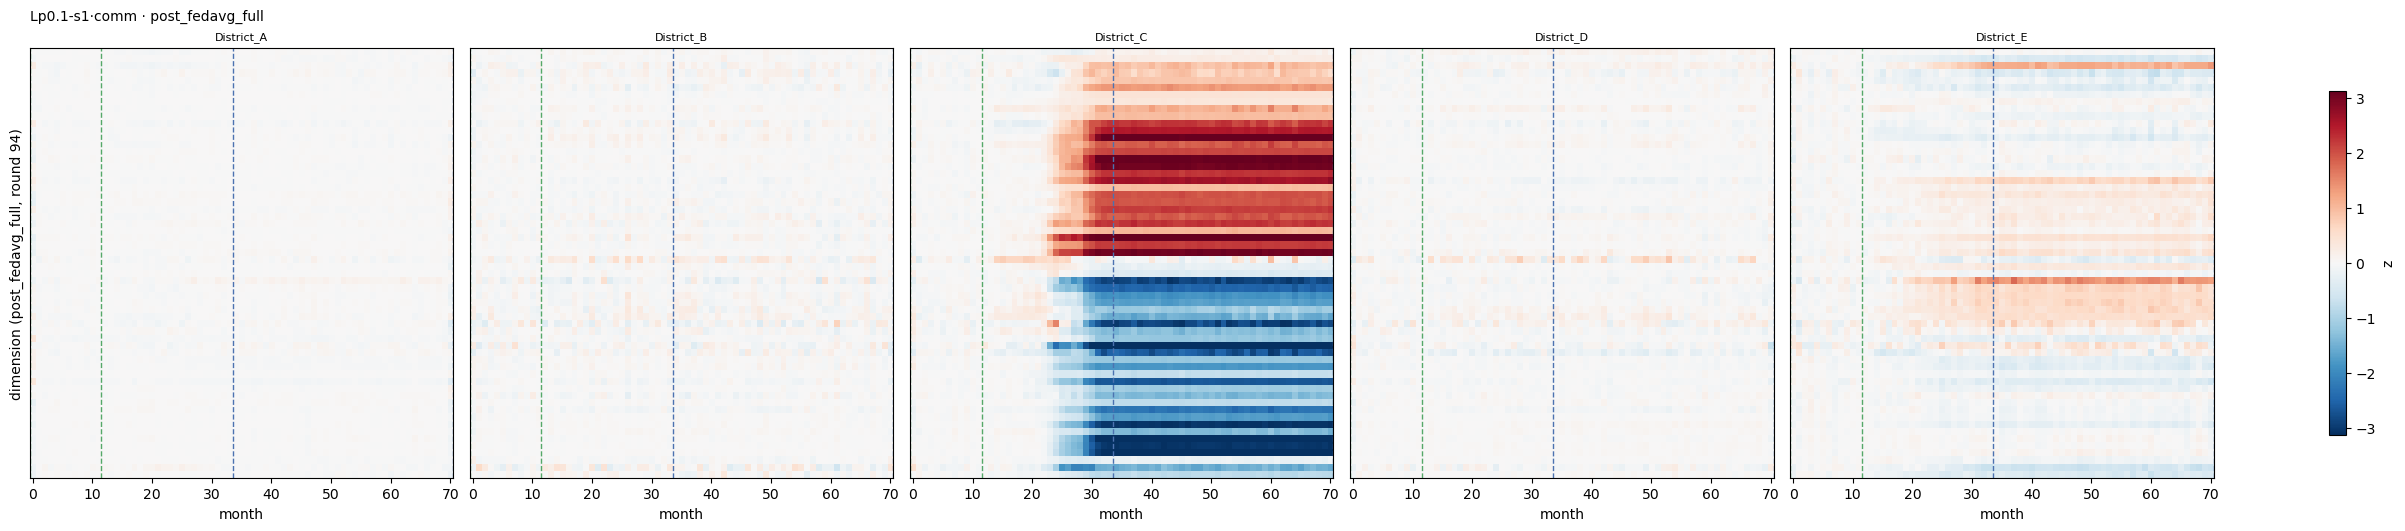

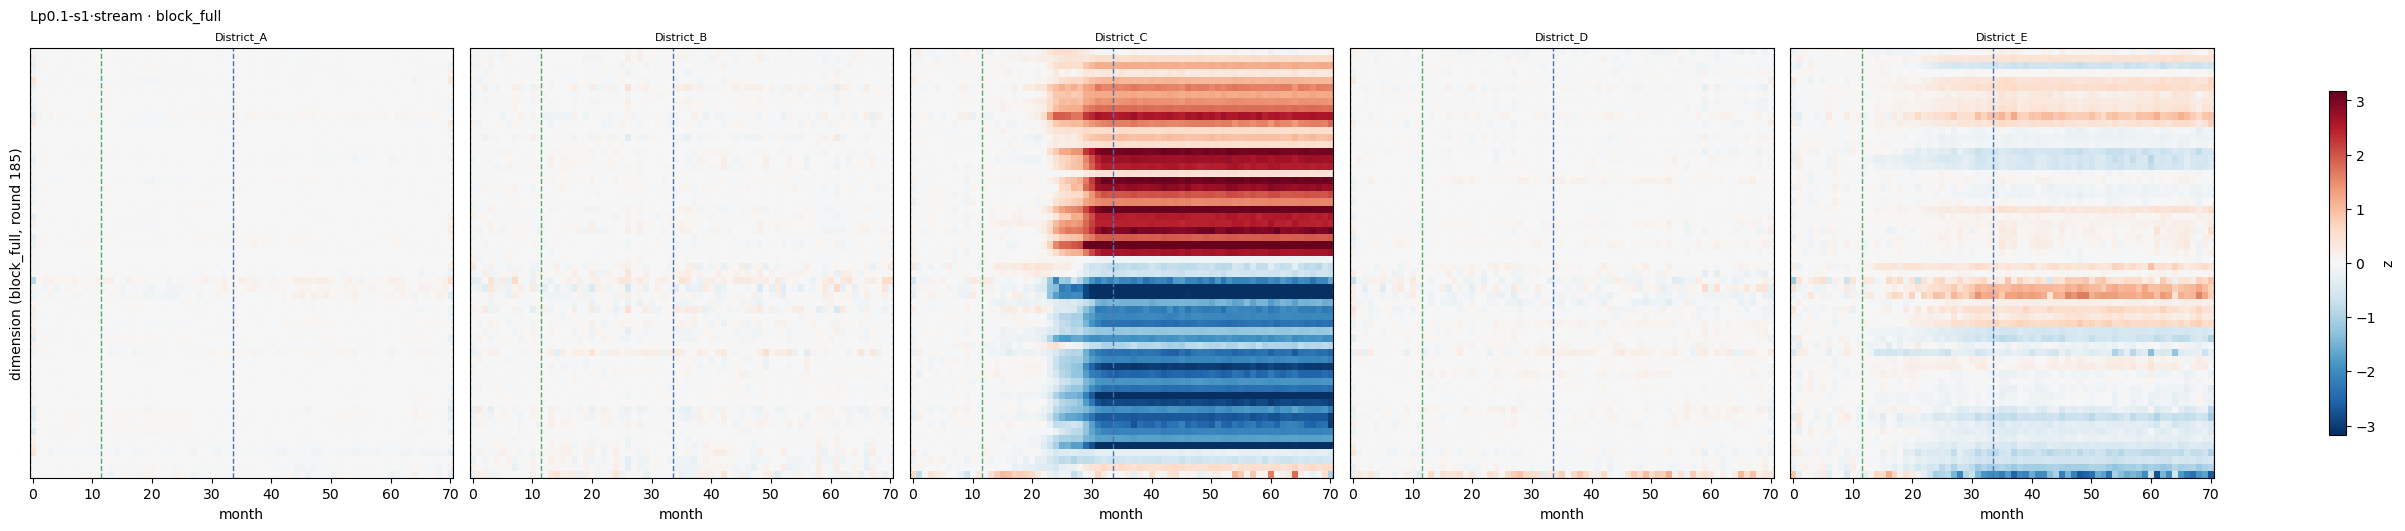

In [8]:
for n, sc, r in PANELS:
    pr = RES[n]["prototypes"]
    nc = pr.loc[pr["scope"] == sc, "client"].nunique()
    fig, axes = plt.subplots(1, nc, sharey=True, figsize=(4.8 * nc, 5.2),
                             layout="constrained")
    im, order = PV.plot_prototype_heatmaps(axes, pr, world, sc, r, feature_labels=False)
    fig.colorbar(im, ax=axes, shrink=0.8, label="z")
    fig.suptitle(f"{n} · {sc}", x=0.01, ha="left", fontsize=10)
    plt.show()

## 5. Streaming — the trajectory as the model learns

Two views per stream run, from `block_full` (global weights at the end of every block, all
months).

**As-of matrix.** $D_c[r, m] = d_c^{(r)}(m)$: the reference distance computed entirely under the
encoder of block-end round $r$ (rows), for every month $m$ (columns). The black staircase is the
last month trained on by round $r$: left of it is in-sample, right of it the model has not seen.

**Honest curve.** For month $m$ in block $b(m)$, use the encoder that ended block $b(m)-1$
($b=0$: the untrained init, round −1):

$$d^{honest}_c(m) = 1-\cos\big(p_c^{(b-1)}(m),\ \mu_c^{init,(b-1)}\big)$$

Month $m$ is unseen by that encoder, and the reference $\mu_c^{init}$ is measured under the
**same** encoder, so each point is internally consistent. It is the prequential latent of
`latent_trajectories_preq` (§3 checks that they are the same numbers), read against a reference
it can actually be compared with. What it does **not** remove: consecutive blocks use different
encoders, so a step at a block boundary can be the model changing rather than the data — compare
clients at the same month (drifting district against the others), not one client across a
boundary. Block 0 is read through an untrained encoder.

Both tables go to `scores/stream_asof`.

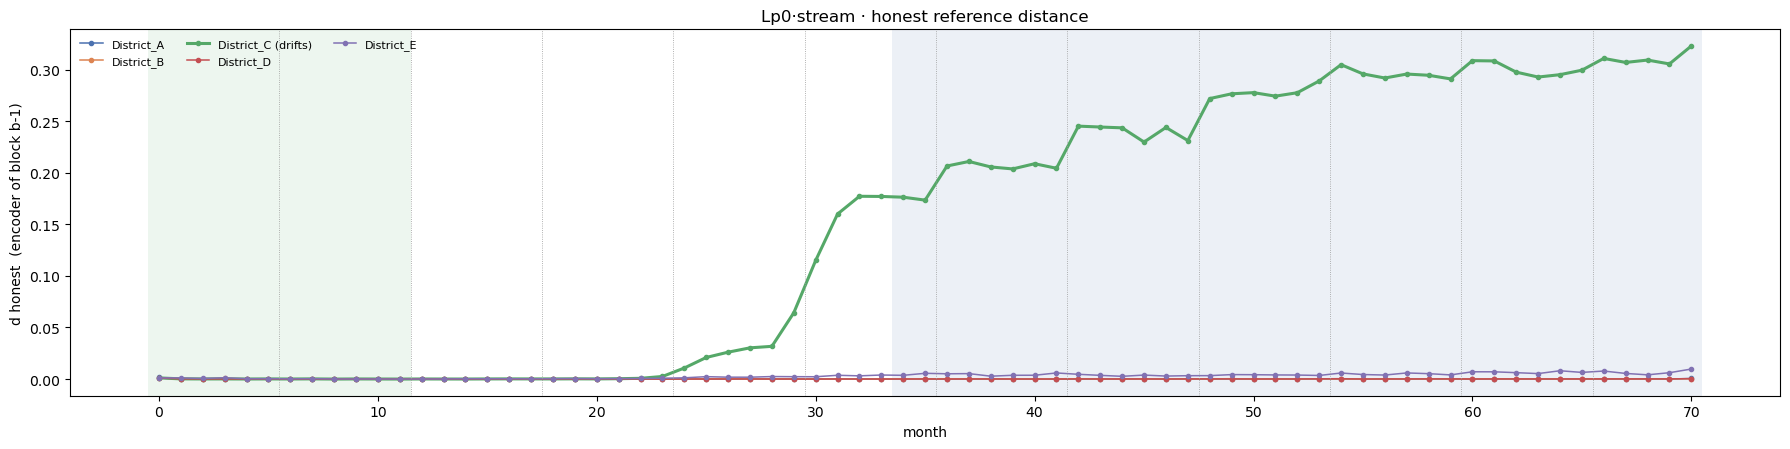

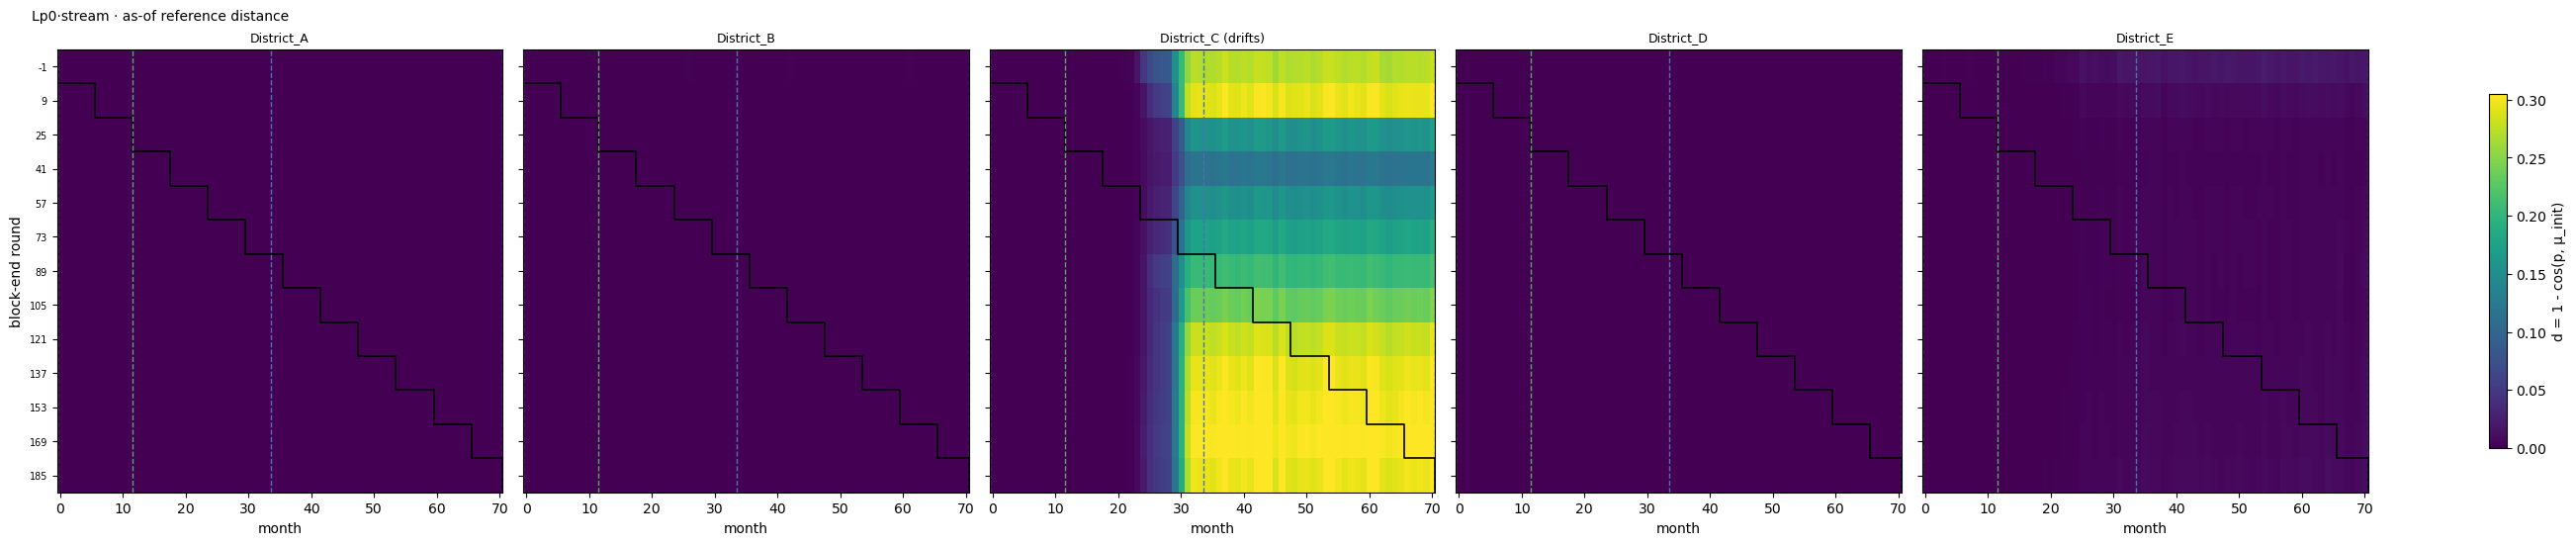

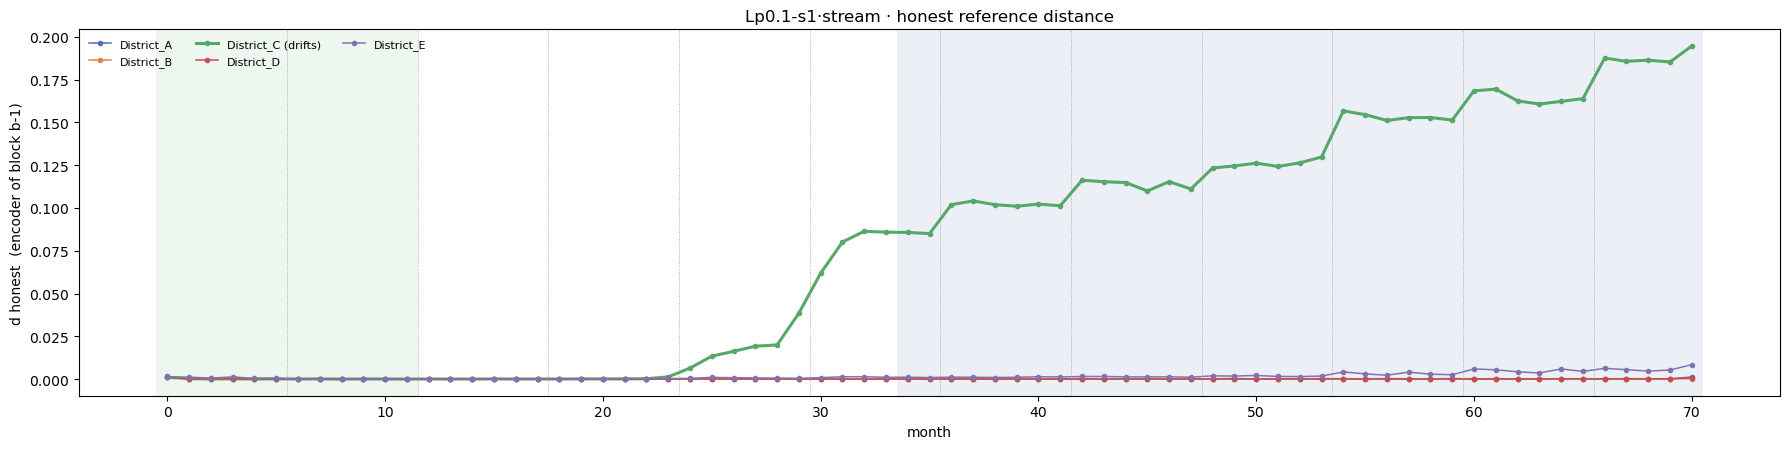

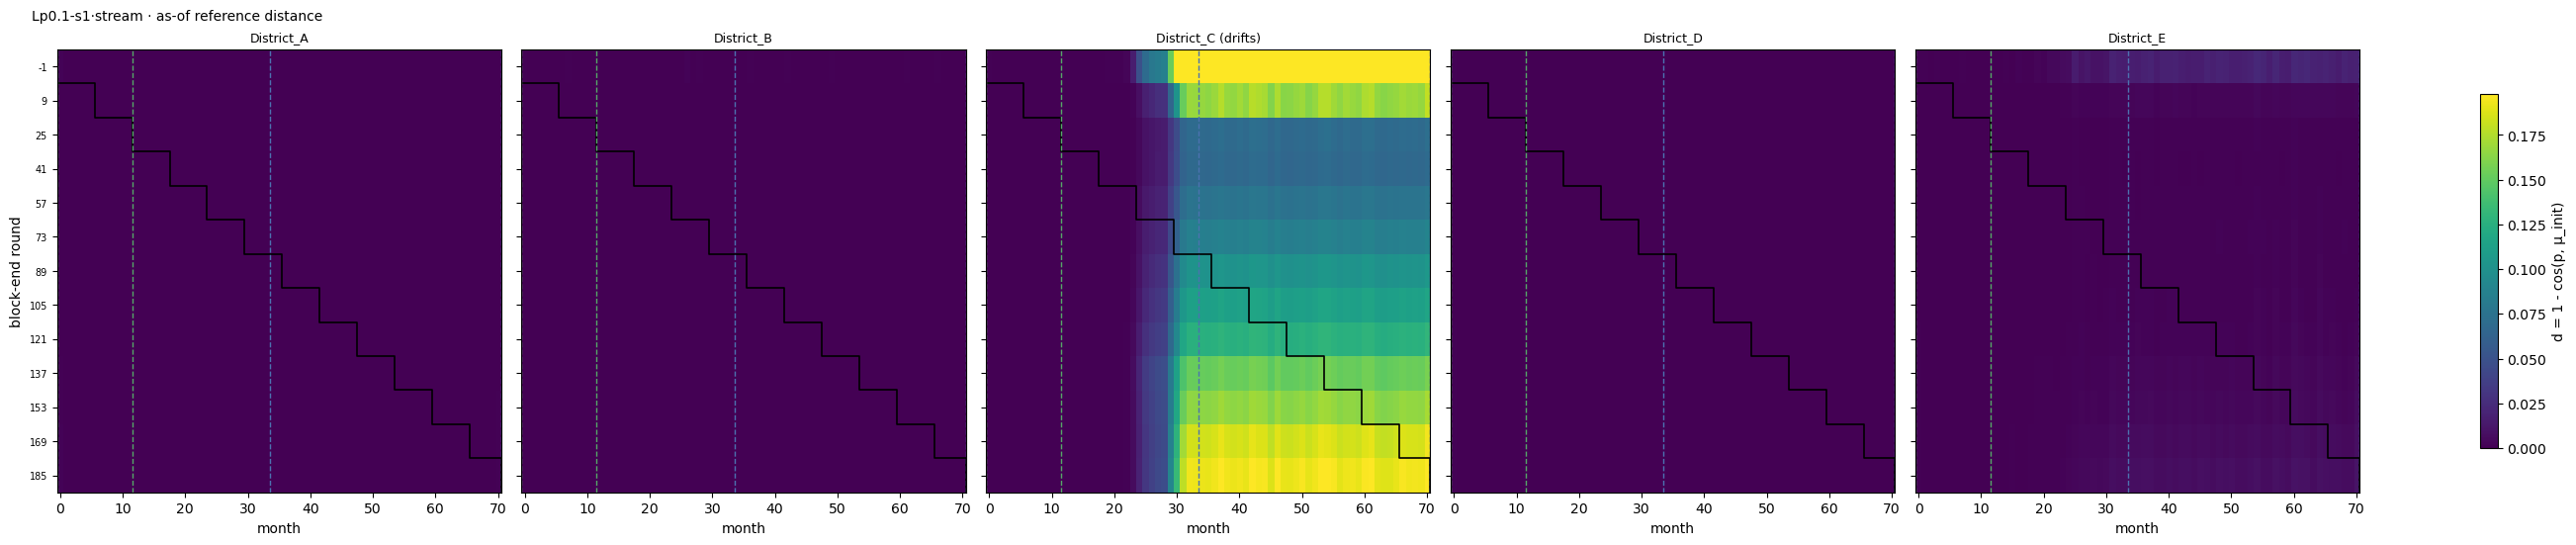

In [9]:
def asof_distance(name) -> pd.DataFrame:
    pr = RES[name]["prototypes"]
    bf = pr[pr["scope"] == "block_full"]
    return pd.concat([PV.reference_distance(bf, world, "block_full", int(r)).assign(round=int(r))
                      for r in sorted(bf["round"].unique())], ignore_index=True)


def honest_curve(name, asof) -> pd.DataFrame:
    blocks = blocks_of(name)
    before = [-1] + blocks["r_hi"].tolist()[:-1]
    return pd.concat([asof[(asof["round"] == rb) & asof["month"].between(b.m_lo, b.m_hi)]
                      .assign(block=int(b.block), encoder_round=rb)
                      for b, rb in zip(blocks.itertuples(), before)], ignore_index=True)


def shade(ax):
    for nm, col in (("init", "#55A868"), ("final", "#4C72B0")):
        lo, hi = PH[nm]
        ax.axvspan(lo - .5, hi - .5, color=col, alpha=.10, lw=0)


STREAM = [n for n in RES if SCHED[n] == "stream"]
ASOF, HONEST = {}, {}
for n in STREAM:
    ASOF[n] = asof_distance(n)
    HONEST[n] = honest_curve(n, ASOF[n])
    blocks = blocks_of(n)
    clients = sorted(ASOF[n]["client"].unique())
    cmap = F.colour_map(clients)

    fig, ax = plt.subplots(figsize=(18, 4.6))
    for c, g in HONEST[n].groupby("client"):
        hot = c == world.drift_district
        ax.plot(g["month"], g["d"], marker="o", ms=3, lw=2.2 if hot else 1.1,
                color=cmap[c], label=f"{c}{' (drifts)' if hot else ''}")
    for m in blocks["m_lo"].iloc[1:]:
        ax.axvline(m - .5, color="0.6", lw=.6, ls=":")
    shade(ax)
    ax.set(xlabel="month", ylabel="d honest  (encoder of block b-1)",
           title=f"{n} · honest reference distance")
    ax.legend(fontsize=8, frameon=False, ncol=3)
    fig.tight_layout()
    plt.show()

    rounds = sorted(ASOF[n]["round"].unique())
    months = np.arange(ASOF[n]["month"].min(), ASOF[n]["month"].max() + 1)
    vmax = float(np.nanquantile(ASOF[n]["d"], 0.99))
    hi_of = dict(zip(blocks["r_hi"], blocks["m_hi"]))
    fig, axes = plt.subplots(1, len(clients), sharey=True, figsize=(5.2 * len(clients), 5.4),
                             layout="constrained")
    for a, c in zip(np.ravel(axes), clients):
        Mx = (ASOF[n][ASOF[n]["client"] == c].pivot(index="round", columns="month", values="d")
              .reindex(index=rounds, columns=months).to_numpy(float))
        im = a.imshow(Mx, aspect="auto", interpolation="nearest", cmap="viridis",
                      vmin=0, vmax=vmax,
                      extent=[months[0] - .5, months[-1] + .5, len(rounds) - .5, -.5])
        # seen boundary: a vertical tick per row at (last trained month + .5)
        xs = np.repeat([hi_of.get(r, months[0] - 1) + .5 for r in rounds], 2)
        ys = np.ravel([[k - .5, k + .5] for k in range(len(rounds))])
        a.plot(xs, ys, color="black", lw=1.2)
        for nm, col in (("init", "#55A868"), ("final", "#4C72B0")):
            for x in (PH[nm][0] - .5, PH[nm][1] - .5):
                a.axvline(x, color=col, lw=1, ls="--")
        a.set_title(f"{c}{' (drifts)' if c == world.drift_district else ''}", fontsize=9)
        a.set_xlabel("month")
    np.ravel(axes)[0].set_yticks(range(len(rounds)))
    np.ravel(axes)[0].set_yticklabels(rounds, fontsize=7)
    np.ravel(axes)[0].set_ylabel("block-end round")
    fig.colorbar(im, ax=axes, shrink=0.8, label="d = 1 - cos(p, μ_init)")
    fig.suptitle(f"{n} · as-of reference distance", x=0.01, ha="left", fontsize=10)
    plt.show()

if STREAM:
    store.save_scores(
        "stream_asof",
        pd.concat([pd.concat({"asof": ASOF[n],
                              "honest": HONEST[n].drop(columns=["block"])},
                             names=["view"]).reset_index(level=0)
                   .assign(run=n, run_key=PICK[n], world_hash=world.sim_hash)
                   for n in STREAM], ignore_index=True),
        keys=("world_hash", "run_key", "view", "round", "client", "month"))

## 6. Latent cloud with trajectories

Windows and the trajectory prototypes through **one** linear map fitted on the prototypes
(`F.project(..., fit_on="prototypes")`, as POC_01 §5). Lines join each client's prototypes in
month order; **filled** markers are months the encoder had trained on, **hollow** ones it had
not (comm: outside the commissioning months; stream: after the block that ends at that round).

* `all`, `comm`: final model, windows sampled from `latent_trajectories`, `post_fedavg_full`.
* `stream`: block-end snapshot at `ROUND` (default the last), stage `post` (global weights —
  `pre` encodes each client with its own local weights, so clients would sit in different
  encoders inside one PCA), with `block_full` at that round.

Each panel has its own projection: different runs (and different stream rounds) are different
encoders, so compare **shapes** across panels, not positions.

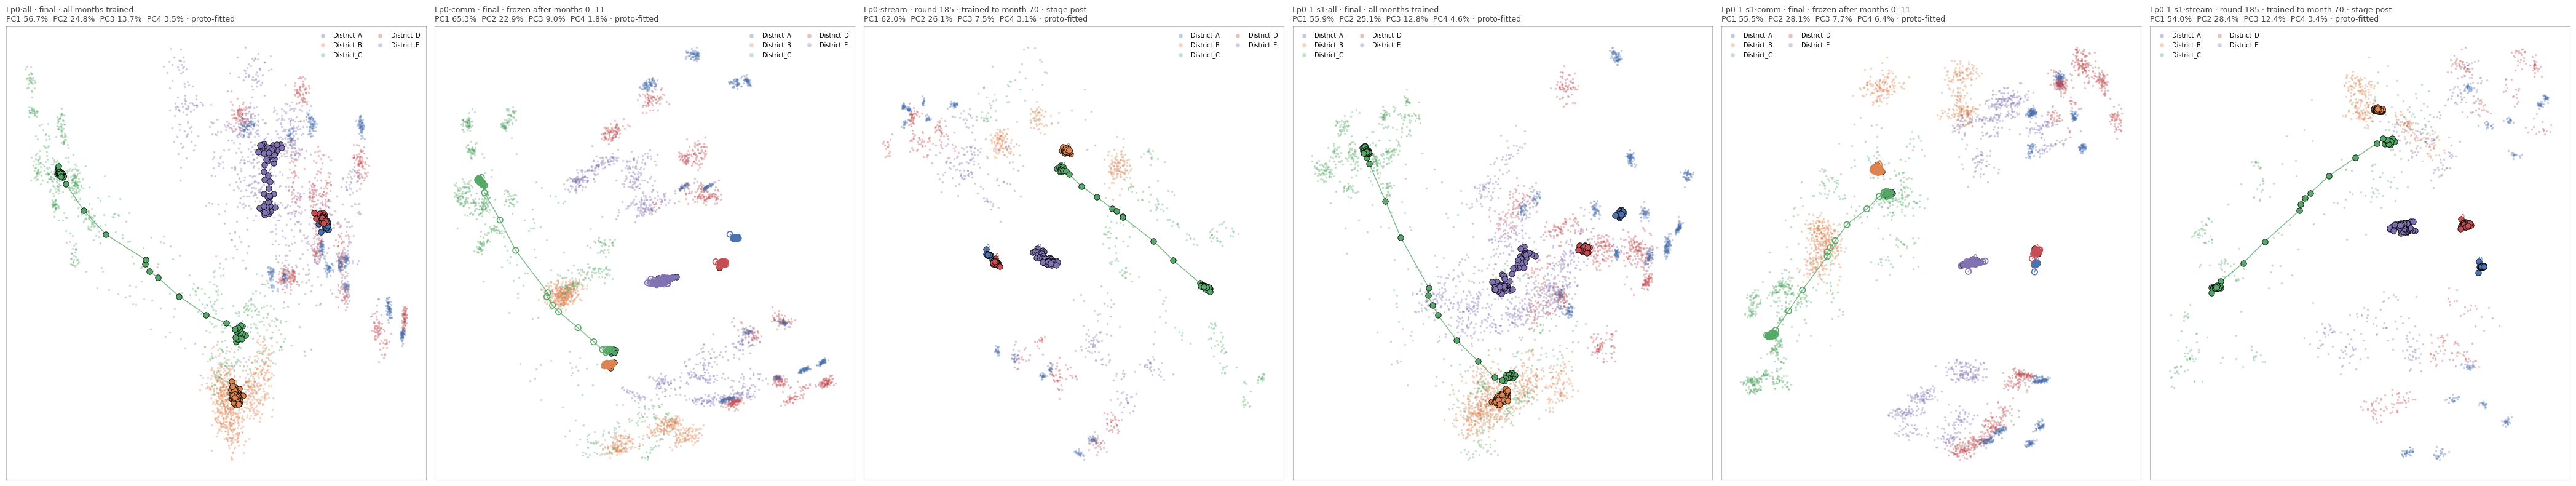

In [10]:
MAX_POINTS = 4000

def cloud_inputs(name, round_=None, stage="post"):
    res, s = RES[name], SCHED[name]
    pr = res["prototypes"]
    if s == "stream":
        rr = sorted(int(r) for r in res["snapshots"]["round"].unique() if r >= 0)
        r = rr[-1] if round_ is None else int(round_)
        d = res["snapshots"]
        d = d[(d["round"] == r) & (d["stage"] == stage)]
        p = pr[(pr["scope"] == "block_full") & (pr["round"] == r)]
        m_hi = dict(zip(blocks_of(name)["r_hi"], blocks_of(name)["m_hi"]))[r]
        seen = lambda m: m <= m_hi
        note = f"round {r} · trained to month {m_hi} · stage {stage}"
    else:
        d = res["latent_trajectories"]
        p = pr[pr["scope"] == "post_fedavg_full"]
        r = int(p["round"].max())
        if s == "comm":
            lo, hi = SPEC[name].schedule.months
            seen = lambda m: (m >= lo) & (m <= hi)
            note = f"final · frozen after months {lo}..{hi}"
        else:
            seen = lambda m: np.ones(len(m), bool)
            note = "final · all months trained"
    if len(d) > MAX_POINTS:
        d = d.sample(MAX_POINTS, random_state=0)
    d = d.sort_values(["district", "window"]).reset_index(drop=True)
    return d, p.reset_index(drop=True), seen, note


def draw_cloud(ax, name, colour_by="district", **kw):
    d, p, seen, note = cloud_inputs(name, **kw)
    Ep, Eq, sub = F.project(d[F.fcols(d)].to_numpy(), p[F.fcols(p)].to_numpy(),
                            "PCA", 0, "prototypes")
    cmap = F.colour_map(sorted(d["district"].unique()))
    F.plot_latent(ax, d, Ep, colour_by=colour_by, subtitle=f"{name} · {note}\n{sub}",
                  cmap=cmap if colour_by == "district" else None)
    for c, g in p.groupby("client"):
        g = g.sort_values("month")
        i = p.index.get_indexer(g.index)
        col = cmap.get(c, "#333333")
        ax.plot(Eq[i, 0], Eq[i, 1], lw=1.0, alpha=.8, color=col, zorder=2)
        sm = np.asarray(seen(g["month"].to_numpy()), bool)
        ax.scatter(Eq[i[sm], 0], Eq[i[sm], 1], s=46, color=col, edgecolor="black",
                   lw=.6, zorder=3)
        ax.scatter(Eq[i[~sm], 0], Eq[i[~sm], 1], s=46, facecolor="none", edgecolor=col,
                   lw=1.2, zorder=3)
        ax.annotate(str(int(g["month"].iloc[0])), (float(Eq[i[0], 0]), float(Eq[i[0], 1])),
                    fontsize=7, color=col)
    if colour_by == "district":
        ax.legend(fontsize=7, frameon=False, markerscale=2, ncol=2)
    return ax


names = list(RES)
fig, axes = plt.subplots(1, len(names), figsize=(7 * len(names), 8), squeeze=False)
for a, n in zip(axes[0], names):
    draw_cloud(a, n)
fig.tight_layout()
plt.show()

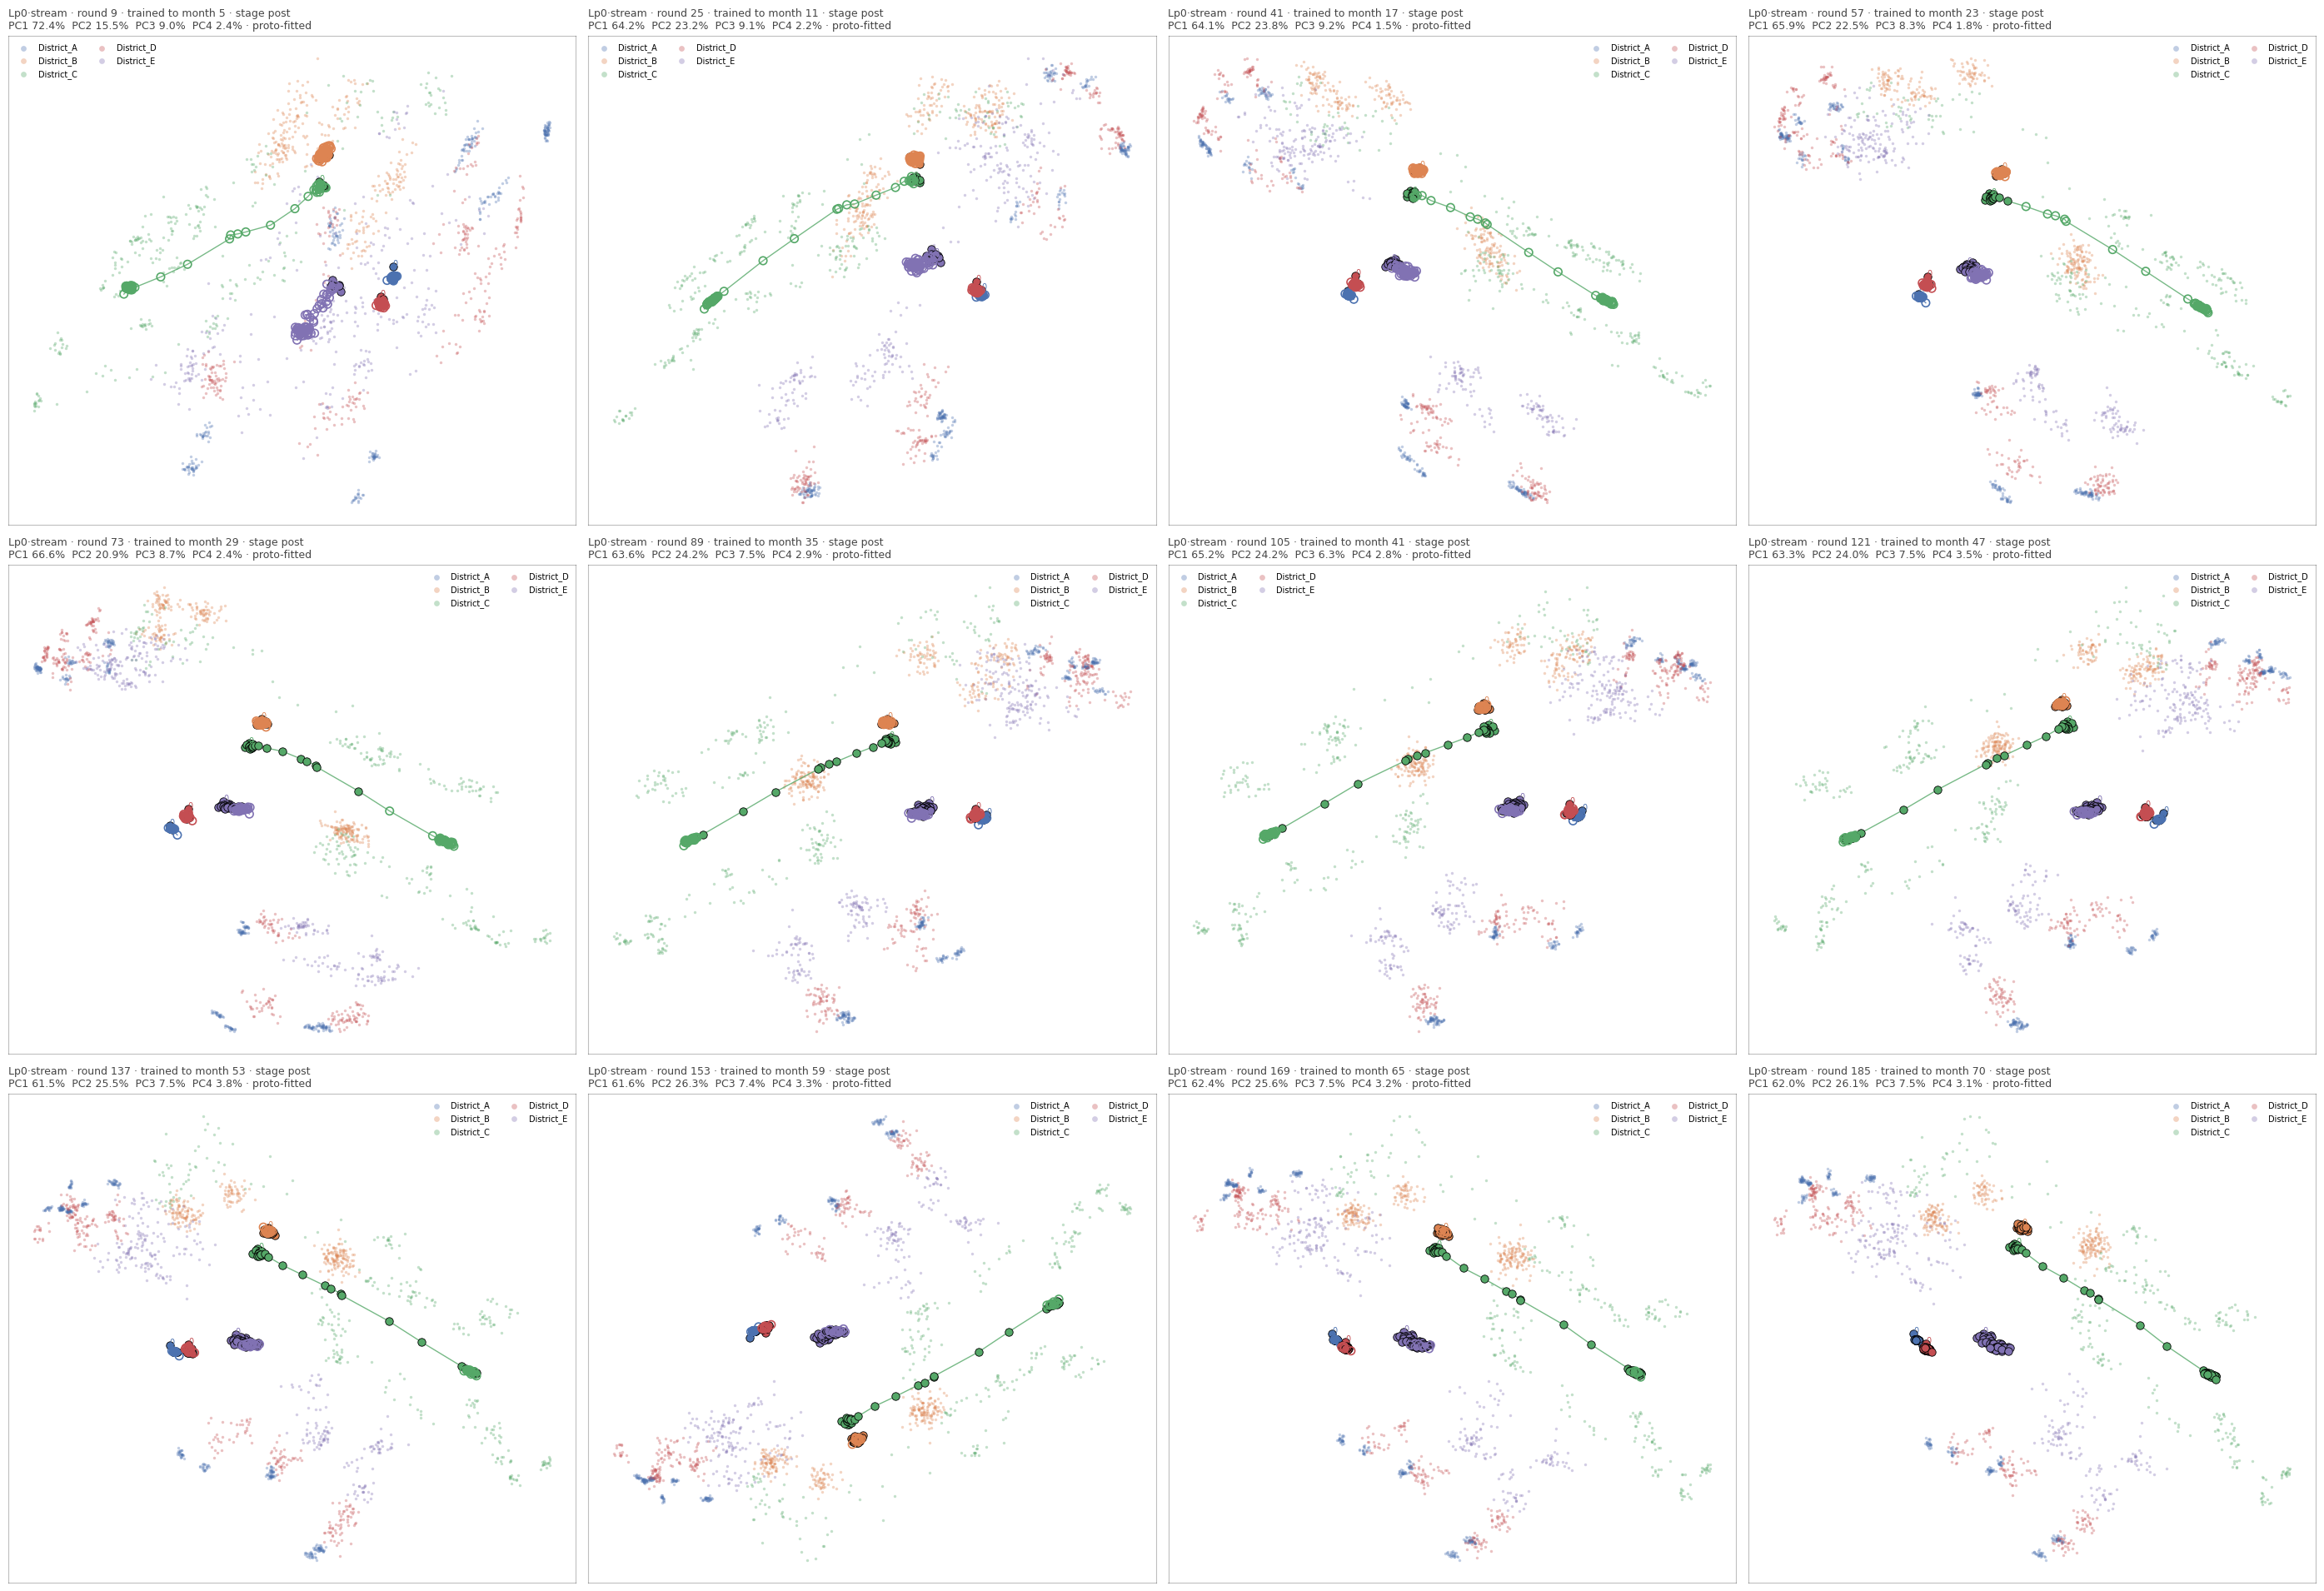

In [11]:
# every block end of one stream run: how the whole-horizon trajectory reshapes as blocks arrive
STREAM_FOCUS = STREAM[0] if STREAM else None
if STREAM_FOCUS:
    rr = blocks_of(STREAM_FOCUS)["r_hi"].tolist()
    ncol = 4
    nrow = int(np.ceil(len(rr) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7 * ncol, 6.4 * nrow), squeeze=False)
    for a, r in zip(axes.ravel(), rr):
        draw_cloud(a, STREAM_FOCUS, round_=r)
    for a in axes.ravel()[len(rr):]:
        a.set_visible(False)
    fig.tight_layout()
    plt.show()

## 7. Interactive browser

`latent_browser` on one run. For stream runs the round slider now walks the block ends (−1 and
every `r_hi`), and the scope list includes `block_full`; its built-in trajectory line joins
`local` prototypes only, so tick `block_full` / `post_fedavg_full` for the markers and use §6 for
the lines.

In [12]:
names

['Lp0·all',
 'Lp0·comm',
 'Lp0·stream',
 'Lp0.1-s1·all',
 'Lp0.1-s1·comm',
 'Lp0.1-s1·stream']

In [13]:
FOCUS = names[0]
_ = WGT.latent_browser(world, RES[FOCUS])

## What to read out of this

* **Is drift visible as a trajectory?** §4: the drifting district's $d$ should leave its init
  level after `first_switch` while the others stay flat. Under `all` the encoder has trained on
  the drift; under `comm` it never has — the comparison is the point.
* **Streaming, honestly.** §5's honest curve is the only full-horizon view in which every month
  is out-of-sample *and* measured against a reference under the same encoder; steps at block
  boundaries are not evidence by themselves.
* **What is still not established:** whether $d$ separates drift from the model adapting
  (stream) or from FedAvg's common mode (all clients moving together) — compare against the
  untrained control (round −1) and across clients before reading levels.